In [6]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
#uploading dataset
from google.colab import files
uploaded = files.upload()

Saving insurance.csv to insurance (1).csv


In [8]:
df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
#Checking rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1338
Number of columns: 7


In [10]:
#Data Quality checks

# Checking dataset information
print("Dataset Information:")
df.info()

# Checking missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Checking duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Checking data types
print("\nData Types:")
print(df.dtypes)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Rows:
1

Data Types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [11]:
# Summary statistics for numerical variables
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [12]:
# Removing duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Checking the dataset after cleaning
print("Rows after cleaning:", df.shape[0])
print("Duplicate rows remaining:", df.duplicated().sum())


Rows after cleaning: 1337
Duplicate rows remaining: 0


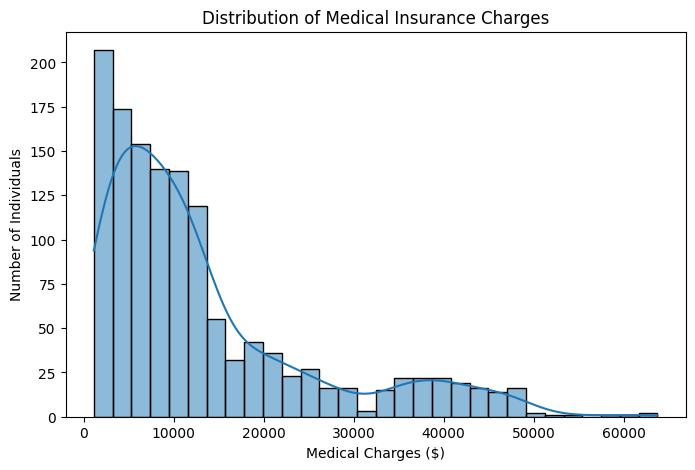

In [13]:
# Histogram of medical insurance charges
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="charges", bins=30, kde=True)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Medical Charges ($)")
plt.ylabel("Number of Individuals")

plt.show()


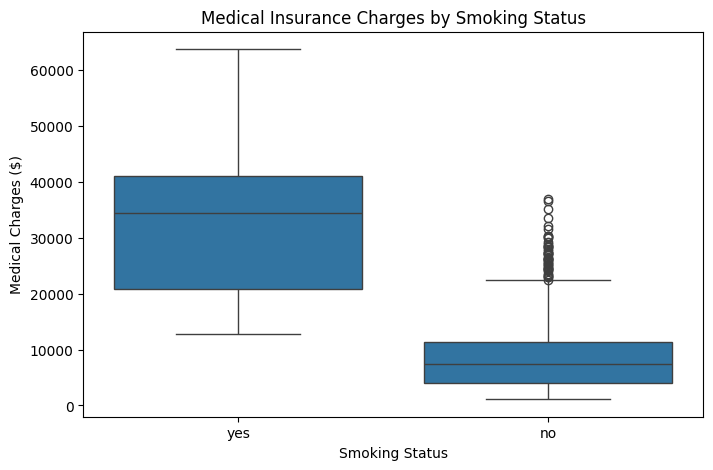

In [14]:
#comparing medical charges by smoking status

# Boxplot of medical charges by smoking status
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Medical Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Medical Charges ($)")

plt.show()


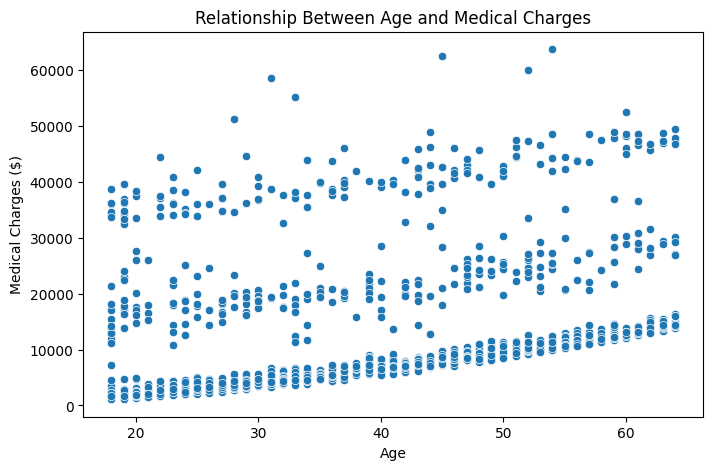

In [16]:
#relationship between age and medical charges

# Scatterplot of age vs medical charges
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="age", y="charges")

plt.title("Relationship Between Age and Medical Charges")
plt.xlabel("Age")
plt.ylabel("Medical Charges ($)")

plt.show()


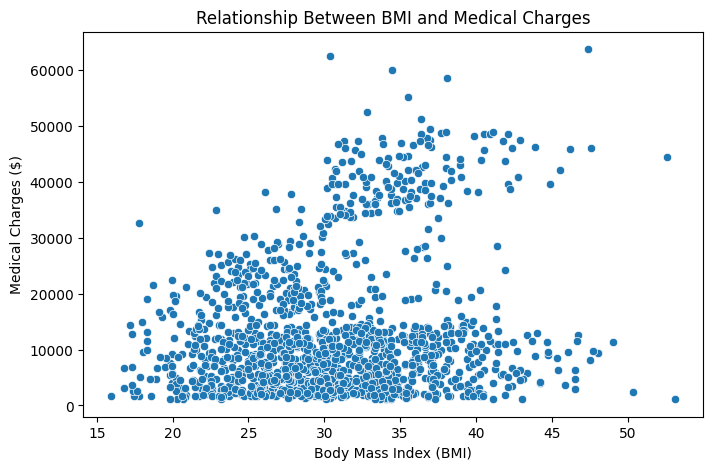

In [17]:

# Scatterplot of BMI vs medical charges
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="bmi", y="charges")

plt.title("Relationship Between BMI and Medical Charges")
plt.xlabel("Body Mass Index (BMI)")
plt.ylabel("Medical Charges ($)")

plt.show()


Correlation Matrix:
            age    bmi  children  charges
age       1.000  0.109     0.042    0.298
bmi       0.109  1.000     0.013    0.198
children  0.042  0.013     1.000    0.067
charges   0.298  0.198     0.067    1.000


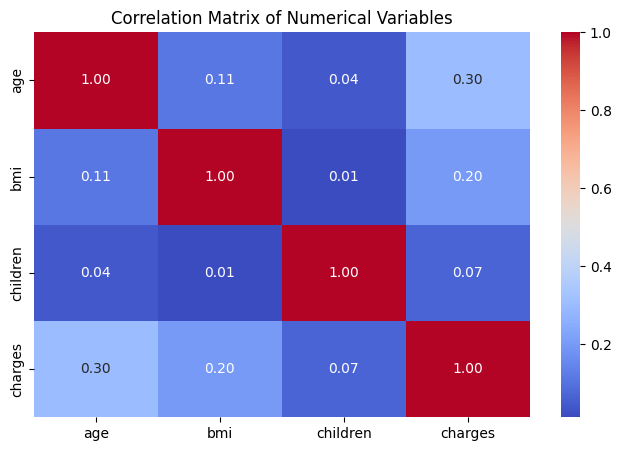

In [18]:

# Correlation analysis
correlation = df[["age", "bmi", "children", "charges"]].corr()

print("Correlation Matrix:")
print(correlation.round(3))

# Correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix of Numerical Variables")
plt.show()


In [19]:

# Compare medical charges between smokers and non-smokers
from scipy.stats import ttest_ind

smokers = df[df["smoker"] == "yes"]["charges"]
non_smokers = df[df["smoker"] == "no"]["charges"]

print("Average charges for smokers:", round(smokers.mean(), 2))
print("Average charges for non-smokers:", round(non_smokers.mean(), 2))

# Welch's independent samples t-test
t_stat, p_value = ttest_ind(smokers, non_smokers, equal_var=False)

print("T-statistic:", round(t_stat, 3))
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference detected")


Average charges for smokers: 32050.23
Average charges for non-smokers: 8440.66
T-statistic: 32.742
P-value: 6.261720774727631e-103
Result: Statistically significant difference


Average Medical Charges by Region:
region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64


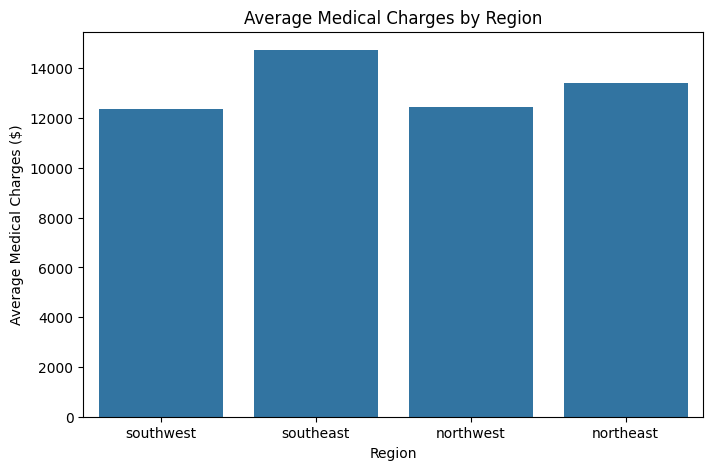

In [20]:

# Average medical charges by region
region_avg = df.groupby("region")["charges"].mean()

print("Average Medical Charges by Region:")
print(region_avg.round(2))

# Bar chart
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="region", y="charges",
            estimator="mean", errorbar=None)

plt.title("Average Medical Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Medical Charges ($)")

plt.show()


In [21]:

# Statistical comparison of medical charges across regions
from scipy.stats import f_oneway, kruskal

regions = [
    group["charges"].values
    for name, group in df.groupby("region")
]

# One-way ANOVA
f_stat, anova_p = f_oneway(*regions)

print("One-way ANOVA Results:")
print("F-statistic:", round(f_stat, 3))
print("P-value:", anova_p)

# Kruskal-Wallis test
h_stat, kruskal_p = kruskal(*regions)

print("\nKruskal-Wallis Test Results:")
print("H-statistic:", round(h_stat, 3))
print("P-value:", kruskal_p)

# Interpretation
if anova_p < 0.05:
    print("\nANOVA: Significant difference detected")
else:
    print("\nANOVA: No statistically significant difference detected")

if kruskal_p < 0.05:
    print("Kruskal-Wallis: Significant difference detected")
else:
    print("Kruskal-Wallis: No statistically significant difference detected")


One-way ANOVA Results:
F-statistic: 2.926
P-value: 0.03276288025444947

Kruskal-Wallis Test Results:
H-statistic: 4.623
P-value: 0.20161983372303882

ANOVA: Significant difference detected
Kruskal-Wallis: No statistically significant difference detected
